
Fetching data for: Pune

Fetching data for: Mumbai

Fetching data for: Delhi

Original Weather Data:
   City  Latitude  Longitude                      Time  Temperature  Humidity  \
0  Pune   18.5204    73.8567 2026-11-01 15:00:00+00:00        26.97        79   
1  Pune   18.5204    73.8567 2026-11-01 18:00:00+00:00        26.72        79   
2  Pune   18.5204    73.8567 2026-11-01 21:00:00+00:00        25.76        83   
3  Pune   18.5204    73.8567 2026-11-02 00:00:00+00:00        25.33        83   
4  Pune   18.5204    73.8567 2026-11-02 03:00:00+00:00        23.91        87   

   WindSpeed  Precipitation  
0       1.00           1.42  
1       0.50           0.22  
2       1.39           1.37  
3       2.73           3.82  
4       2.17           0.56  

Dataset Shape: (120, 8)

Cleaned Weather Data:
     City  Latitude  Longitude                      Time  Temperature  \
80  Delhi   28.6139     77.209 2026-11-01 20:30:00+05:30        23.46   
81  Delhi   28.6139     77.209 2026-1

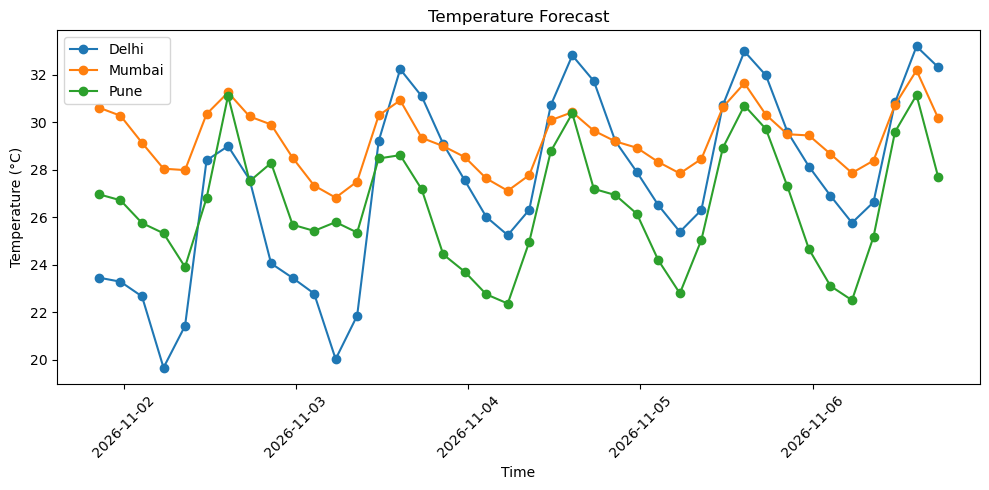

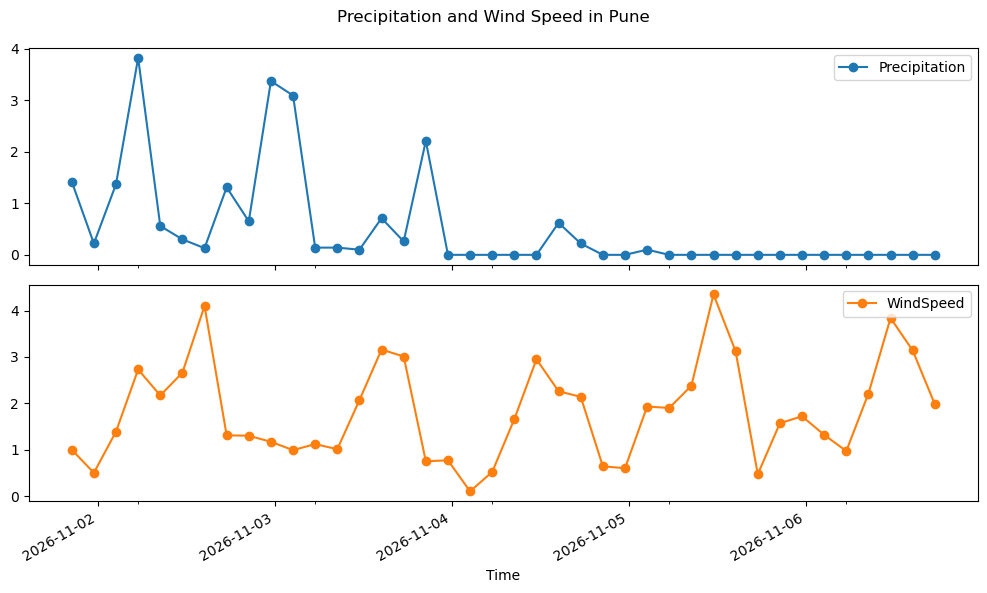


========== DAILY AVERAGES ==========
                   Temperature  Humidity  WindSpeed  Precipitation
City   Date                                                       
Delhi  2026-11-01        23.38     48.50       1.10           0.00
       2026-11-02        24.53     30.00       1.22           0.00
       2026-11-03        26.74     22.62       1.73           0.00
       2026-11-04        28.75     20.75       1.78           0.00
       2026-11-05        28.96     20.00       1.56           0.00
       2026-11-06        29.28     19.50       1.96           0.00
Mumbai 2026-11-01        30.45     63.00       3.41           0.08
       2026-11-02        29.43     65.38       2.27           0.02
       2026-11-03        28.72     67.50       2.03           0.13
       2026-11-04        28.86     66.88       2.42           0.00
       2026-11-05        29.52     64.75       2.49           0.00
       2026-11-06        29.68     60.17       2.92           0.00
Pune   2026-11-01       

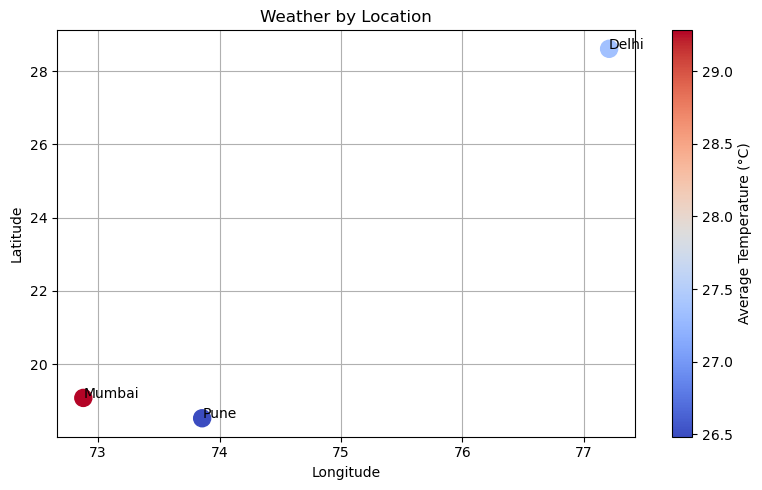

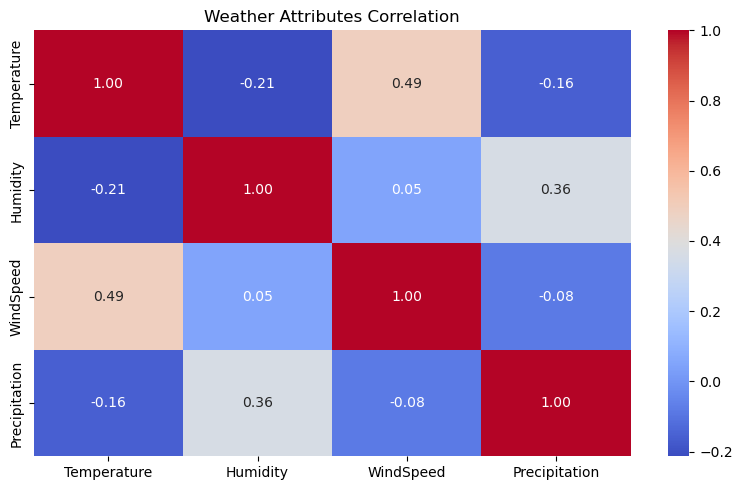


All weather analysis completed successfully!
Weather datasets saved as CSV files.


In [1]:

import requests
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# 1. API KEY
API_KEY = "0bfe84d51e131eb0db13316f25fb48ed"

# 2. GET WEATHER DATA FOR THREE CITIES
cities = {
    "Pune": (18.5204, 73.8567),
    "Mumbai": (19.0760, 72.8777),
    "Delhi": (28.6139, 77.2090)
}

url = "https://api.openweathermap.org/data/2.5/forecast"

rows = []

for city, (lat, lon) in cities.items():

    print("\nFetching data for:", city)

    try:
        r = requests.get(url, params={
            "lat": lat,
            "lon": lon,
            "appid": API_KEY,
            "units": "metric"
        }, timeout=20)

        r.raise_for_status()
        data = r.json()

        # Extract weather attributes
        for w in data["list"]:
            rows.append([
                city,
                lat,
                lon,
                pd.to_datetime(w["dt"], unit="s", utc=True),
                w["main"].get("temp"),
                w["main"].get("humidity"),
                w.get("wind", {}).get("speed"),
                w.get("rain", {}).get("3h", 0)
            ])

    except requests.exceptions.RequestException as e:
        print("API Error for", city, ":", e)
        continue


# 3. CREATE DATAFRAME
df = pd.DataFrame(rows, columns=[
    "City", "Latitude", "Longitude", "Time",
    "Temperature", "Humidity", "WindSpeed", "Precipitation"
])

if df.empty:
    raise SystemExit("No weather data found. Check API key and internet connection.")

print("\nOriginal Weather Data:")
print(df.head())

print("\nDataset Shape:", df.shape)


# 4. DATA CLEANING AND PREPROCESSING

# Convert UTC time to Indian Standard Time
df["Time"] = df["Time"].dt.tz_convert("Asia/Kolkata")

# Convert columns into numeric format
cols = ["Temperature", "Humidity", "WindSpeed", "Precipitation"]

df[cols] = df[cols].apply(pd.to_numeric, errors="coerce")

# Handle missing values
df["Precipitation"] = df["Precipitation"].fillna(0)

df[cols] = df[cols].fillna(df[cols].median())

# Remove duplicate records
df.drop_duplicates(subset=["City", "Time"], inplace=True)

# Remove rows with missing essential values
df.dropna(subset=["Time", "Temperature", "Humidity", "WindSpeed"], inplace=True)

# Sort data by city and time
df.sort_values(["City", "Time"], inplace=True)

print("\nCleaned Weather Data:")
print(df.head())

print("\nMissing Values:")
print(df.isnull().sum())


# 5. STATISTICAL ANALYSIS

print("\n========== WEATHER STATISTICS ==========")

print(df.groupby("City")[cols].agg(
    ["mean", "min", "max"]
).round(2))


# 6. TEMPERATURE CHANGES OVER TIME

plt.figure(figsize=(10, 5))

for city, d in df.groupby("City"):
    plt.plot(d["Time"], d["Temperature"], marker="o", label=city)

plt.xlabel("Time")
plt.ylabel("Temperature (°C)")
plt.title("Temperature Forecast")
plt.legend()
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


# PRECIPITATION AND WIND SPEED FOR PUNE

pune = df[df["City"] == "Pune"]

pune.plot(
    x="Time",
    y=["Precipitation", "WindSpeed"],
    subplots=True,
    marker="o",
    figsize=(10, 6)
)

plt.suptitle("Precipitation and Wind Speed in Pune")
plt.tight_layout()
plt.show()


# 7. DATA AGGREGATION

# Daily averages
df["Date"] = df["Time"].dt.date

daily = df.groupby(["City", "Date"])[cols].mean().round(2)

print("\n========== DAILY AVERAGES ==========")
print(daily)


# Monthly averages
df["Month"] = df["Time"].dt.month

monthly = df.groupby(["City", "Month"])[cols].mean().round(2)

print("\n========== MONTHLY AVERAGES ==========")
print(monthly)


# Seasonal averages
def get_season(month):

    if month in [12, 1, 2]:
        return "Winter"

    elif month in [3, 4, 5]:
        return "Summer"

    elif month in [6, 7, 8, 9]:
        return "Monsoon"

    else:
        return "Post-Monsoon"


df["Season"] = df["Time"].dt.month.map(get_season)

seasonal = df.groupby(["City", "Season"])[cols].mean().round(2)

print("\n========== SEASONAL AVERAGES ==========")
print(seasonal)


# 8. GEOGRAPHICAL VISUALIZATION

geo = df.groupby("City").agg(
    Latitude=("Latitude", "first"),
    Longitude=("Longitude", "first"),
    Temperature=("Temperature", "mean")
)

plt.figure(figsize=(8, 5))

scatter = plt.scatter(
    geo["Longitude"],
    geo["Latitude"],
    c=geo["Temperature"],
    s=150,
    cmap="coolwarm"
)

for city, row in geo.iterrows():
    plt.text(row["Longitude"], row["Latitude"], city)

plt.colorbar(scatter, label="Average Temperature (°C)")
plt.xlabel("Longitude")
plt.ylabel("Latitude")
plt.title("Weather by Location")
plt.grid()
plt.tight_layout()
plt.show()


# 9. CORRELATION ANALYSIS

plt.figure(figsize=(8, 5))

sns.heatmap(
    df[cols].corr(),
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Weather Attributes Correlation")
plt.tight_layout()
plt.show()


# 10. SAVE DATASETS

df.to_csv("weather_data.csv", index=False)

daily.to_csv("daily_weather_summary.csv")

monthly.to_csv("monthly_weather_summary.csv")

seasonal.to_csv("seasonal_weather_summary.csv")

print("\nAll weather analysis completed successfully!")

print("Weather datasets saved as CSV files.")
